In [2]:
!pip install -q kaggle

In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"prateekdhakar","key":"4608ccf20d81d4aa1797f7827297e98a"}'}

In [4]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

In [5]:
!kaggle competitions download -c house-prices-advanced-regression-techniques

100% 199k/199k [00:00<00:00, 47.9MB/s]



In [6]:
!unzip -o house-prices-advanced-regression-techniques.zip -d /content/house_prices

Archive:  house-prices-advanced-regression-techniques.zip
  inflating: /content/house_prices/data_description.txt  
  inflating: /content/house_prices/sample_submission.csv  
  inflating: /content/house_prices/test.csv  
  inflating: /content/house_prices/train.csv  


In [7]:
import os

print(os.listdir("/content/house_prices"))

['train.csv', 'data_description.txt', 'sample_submission.csv', 'test.csv']


In [8]:
import pandas as pd

df = pd.read_csv("/content/house_prices/train.csv")
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [9]:
print(df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [11]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [12]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=True)

print(missing)

Electrical         1
MasVnrArea         8
BsmtCond          37
BsmtFinType1      37
BsmtQual          37
BsmtExposure      38
BsmtFinType2      38
GarageType        81
GarageQual        81
GarageFinish      81
GarageCond        81
GarageYrBlt       81
LotFrontage      259
FireplaceQu      690
MasVnrType       872
Fence           1179
Alley           1369
MiscFeature     1406
PoolQC          1453
dtype: int64


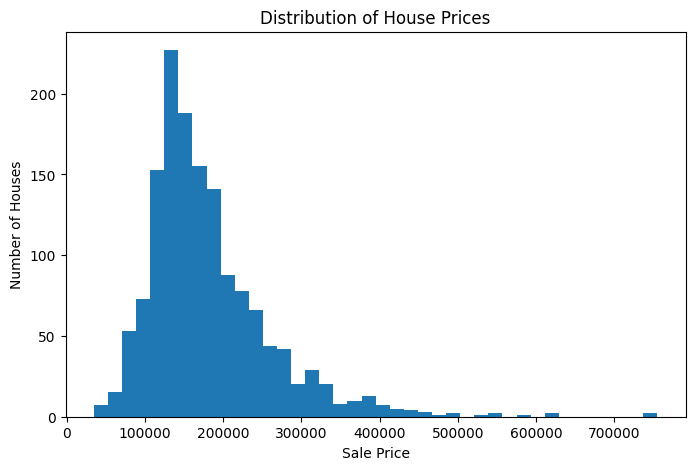

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["SalePrice"], bins=40)
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")
plt.show()

In [14]:
missing_count = df.isnull().sum()

missing_percent = (missing_count / len(df)) * 100

missing_info = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

missing_info = missing_info[missing_info["Missing_Count"] > 0]
missing_info = missing_info.sort_values(
    by="Missing_Percent",
    ascending=False
)

print(missing_info.round(2))

              Missing_Count  Missing_Percent
PoolQC                 1453            99.52
MiscFeature            1406            96.30
Alley                  1369            93.77
Fence                  1179            80.75
MasVnrType              872            59.73
FireplaceQu             690            47.26
LotFrontage             259            17.74
GarageType               81             5.55
GarageYrBlt              81             5.55
GarageFinish             81             5.55
GarageQual               81             5.55
GarageCond               81             5.55
BsmtExposure             38             2.60
BsmtFinType2             38             2.60
BsmtQual                 37             2.53
BsmtCond                 37             2.53
BsmtFinType1             37             2.53
MasVnrArea                8             0.55
Electrical                1             0.07


In [15]:
len(df)

1460

In [16]:
missing_col = df.columns[df.isnull().any()]

for col in missing_col:
  print(col, "->" , df[col].dtype, "->", df[col].isnull().sum())

LotFrontage -> float64 -> 259
Alley -> object -> 1369
MasVnrType -> object -> 872
MasVnrArea -> float64 -> 8
BsmtQual -> object -> 37
BsmtCond -> object -> 37
BsmtExposure -> object -> 38
BsmtFinType1 -> object -> 37
BsmtFinType2 -> object -> 38
Electrical -> object -> 1
FireplaceQu -> object -> 690
GarageType -> object -> 81
GarageYrBlt -> float64 -> 81
GarageFinish -> object -> 81
GarageQual -> object -> 81
GarageCond -> object -> 81
PoolQC -> object -> 1453
Fence -> object -> 1179
MiscFeature -> object -> 1406


In [17]:
cols_to_check = [
    "MasVnrType",
    "MasVnrArea",
    "GarageYrBlt",
    "LotFrontage",
    "Electrical"
]

for col in cols_to_check:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))


--- MasVnrType ---
MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

--- MasVnrArea ---
MasVnrArea
0.0      861
108.0      8
NaN        8
72.0       8
180.0      8
120.0      7
16.0       7
340.0      6
80.0       6
200.0      6
Name: count, dtype: int64

--- GarageYrBlt ---
GarageYrBlt
NaN       81
2005.0    65
2006.0    59
2004.0    53
2003.0    50
2007.0    49
1977.0    35
1998.0    31
1999.0    30
1976.0    29
Name: count, dtype: int64

--- LotFrontage ---
LotFrontage
NaN     259
60.0    143
70.0     70
80.0     69
50.0     57
75.0     53
65.0     44
85.0     40
78.0     25
21.0     23
Name: count, dtype: int64

--- Electrical ---
Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64


In [18]:
garage_cols = [
    "GarageType",
    "GarageYrBlt",
    "GarageFinish",
    "GarageCars",
    "GarageArea",
    "GarageQual",
    "GarageCond"
]

print(df.loc[df["GarageYrBlt"].isnull(), garage_cols].head(10))

    GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual  \
39         NaN          NaN          NaN           0           0        NaN   
48         NaN          NaN          NaN           0           0        NaN   
78         NaN          NaN          NaN           0           0        NaN   
88         NaN          NaN          NaN           0           0        NaN   
89         NaN          NaN          NaN           0           0        NaN   
99         NaN          NaN          NaN           0           0        NaN   
108        NaN          NaN          NaN           0           0        NaN   
125        NaN          NaN          NaN           0           0        NaN   
127        NaN          NaN          NaN           0           0        NaN   
140        NaN          NaN          NaN           0           0        NaN   

    GarageCond  
39         NaN  
48         NaN  
78         NaN  
88         NaN  
89         NaN  
99         NaN  
108        

In [19]:
df_processed = df.copy()

In [20]:
garage_cat_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

df_processed[garage_cat_cols] = (
    df_processed[garage_cat_cols].fillna("None")
)

df_processed["GarageYrBlt"] = (
    df_processed["GarageYrBlt"].fillna(0)
)

In [21]:
df_processed["MasVnrType"] = (
    df_processed["MasVnrType"].fillna("None")
)

df_processed["MasVnrArea"] = (
    df_processed["MasVnrArea"].fillna(0)
)

In [22]:
df_processed["Electrical"] = (
    df_processed["Electrical"].fillna(
        df_processed["Electrical"].mode()[0]
    )
)

In [23]:
none_cols = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

df_processed[none_cols] = (
    df_processed[none_cols].fillna("None")
)

In [24]:
df_processed["LotFrontage"] = (
    df_processed["LotFrontage"].fillna(
        df_processed["LotFrontage"].median()
    )
)

In [25]:
missing_after = df_processed.isnull().sum()

print(missing_after[missing_after > 0])

Series([], dtype: int64)


In [26]:
print(df_processed.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [27]:
X = df_processed.drop("SalePrice", axis=1)
y = df_processed["SalePrice"]

In [28]:
print("Numerical columns:", len(X.select_dtypes(include="number").columns))
print("Categorical columns:", len(X.select_dtypes(exclude="number").columns))

Numerical columns: 37
Categorical columns: 43


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 80)
X_test: (292, 80)
y_train: (1168,)
y_test: (292,)


In [30]:
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()


print("Categorical columns:", len(cat_cols))
print("Numerical columns:", len(num_cols))

Categorical columns: 43
Numerical columns: 37


In [31]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

print("X_train_cat:", X_train_cat.shape)
print("X_test_cat:", X_test_cat.shape)

X_train_cat: (1168, 264)
X_test_cat: (292, 264)


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

print("X_train_num:", X_train_num.shape)
print("X_test_num:", X_test_num.shape)

X_train_num: (1168, 37)
X_test_num: (292, 37)


In [33]:
import numpy as np

X_train_final = np.concatenate(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat],
    axis=1
)

print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)

X_train_final: (1168, 301)
X_test_final: (292, 301)


In [34]:
import torch

X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([1168, 301])
y_train: torch.Size([1168, 1])
X_test: torch.Size([292, 301])
y_test: torch.Size([292, 1])


In [35]:
print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([1168, 301])
y_train: torch.Size([1168, 1])
X_test: torch.Size([292, 301])
y_test: torch.Size([292, 1])


In [36]:
import torch
import torch.nn as nn

class HousesModelANN(nn.Module):
    def __init__(self, input_features):
        super().__init__()

        self.network = nn.Sequential(

              nn.Linear(input_features, 128),
              nn.ReLU(),
              nn.Dropout(0.2),

              nn.Linear(128, 64),
              nn.ReLU(),
              nn.Dropout(0.2),

              nn.Linear(64, 1)
        )

    def forward(self, x):
       return self.network(x)


In [37]:

from sklearn.preprocessing import StandardScaler

# Target scaler
y_scaler = StandardScaler()

# Training target par fit
y_train_scaled = y_scaler.fit_transform(
    y_train_tensor.numpy()
)

# Test target par sirf transform
y_test_scaled = y_scaler.transform(
    y_test_tensor.numpy()
)

# NumPy arrays ko PyTorch tensors mein convert karo
y_train_scaled = torch.tensor(
    y_train_scaled, dtype=torch.float32
)

y_test_scaled = torch.tensor(
    y_test_scaled, dtype=torch.float32
)

print("Scaled train target:", y_train_scaled.shape)
print("Scaled test target:", y_test_scaled.shape)



Scaled train target: torch.Size([1168, 1])
Scaled test target: torch.Size([292, 1])


In [38]:

from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_tensor,
    y_train_scaled,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train_sub.shape, y_train_sub.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test_tensor.shape, y_test_scaled.shape)

Training: torch.Size([934, 301]) torch.Size([934, 1])
Validation: torch.Size([234, 301]) torch.Size([234, 1])
Test: torch.Size([292, 301]) torch.Size([292, 1])


In [39]:

import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Fresh model
model = HousesModelANN(
    input_features=X_train_sub.shape[1]
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

loss_function = nn.MSELoss()

epochs = 200
patience = 10

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training
    model.train()

    optimizer.zero_grad()

    train_predictions = model(X_train_sub)

    train_loss = loss_function(
        train_predictions,
        y_train_sub
    )

    train_loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)

        val_loss = loss_function(
            val_predictions,
            y_val
        )

    # Best model save karna
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Har 10 epochs par progress
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch: {epoch + 1}, "
            f"Train Loss: {train_loss.item():.4f}, "
            f"Val Loss: {val_loss.item():.4f}"
        )

    # Early stopping
    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

# Best model restore karna
model.load_state_dict(best_model_state)

print(f"Best Validation Loss: {best_val_loss:.4f}")



Epoch: 10, Train Loss: 0.4551, Val Loss: 0.4363
Epoch: 20, Train Loss: 0.2586, Val Loss: 0.1990
Epoch: 30, Train Loss: 0.2007, Val Loss: 0.1656
Epoch: 40, Train Loss: 0.1505, Val Loss: 0.1348

Early stopping at epoch 48
Best Validation Loss: 0.1341


In [40]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model.eval()

with torch.no_grad():
    test_predictions_scaled = model(X_test_tensor)

# Predictions ko original dollar scale mein convert karo
test_predictions_original = y_scaler.inverse_transform(
    test_predictions_scaled.numpy()
).ravel()

actual_prices = y_test_tensor.numpy().ravel()

# Evaluation metrics
mae = mean_absolute_error(
    actual_prices,
    test_predictions_original
)

rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        test_predictions_original
    )
)

r2 = r2_score(
    actual_prices,
    test_predictions_original
)

print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"R² Percentage: {r2 * 100:.2f}%")




MAE: $19,634.06
RMSE: $33,148.54
R² Score: 0.8567
R² Percentage: 85.67%


In [42]:

model.eval()

with torch.no_grad():
    # Training data par predictions
    train_predictions_scaled = model(X_train_tensor)

    # Test data par predictions
    test_predictions_scaled = model(X_test_tensor)

    # Scaled target par MSE
    train_loss = loss_function(
        train_predictions_scaled,
        y_train_scaled
    )

    test_loss = loss_function(
        test_predictions_scaled,
        y_test_scaled
    )

print(f"Train Loss: {train_loss.item():.4f}")
print(f"Test Loss: {test_loss.item():.4f}")


Train Loss: 0.1206
Test Loss: 0.1842


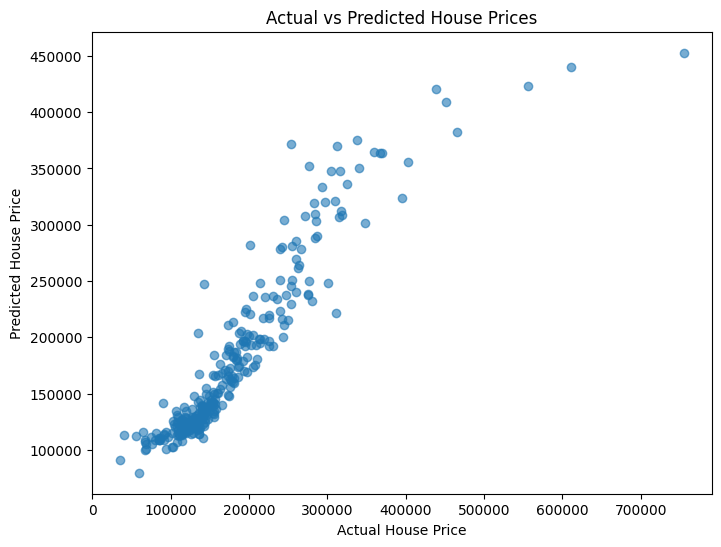

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(actual_prices, test_predictions_original, alpha=0.6)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [44]:
import pandas as pd
import numpy as np

results = pd.DataFrame({
    "Actual Price": actual_prices,
    "Predicted Price": test_predictions_original
})

results["Error"] = (
    results["Actual Price"] - results["Predicted Price"]
)

results["Absolute Error"] = results["Error"].abs()

results = results.sort_values(
    by="Absolute Error",
    ascending=False
)

results.head(10)

,Actual Price,Predicted Price,Error,Absolute Error
139,755000.0,452755.218750,302244.781250,302244.781250
74,611657.0,440415.093750,171241.906250,171241.906250
168,556581.0,423599.343750,132981.656250,132981.656250
43,253293.0,371553.468750,-118260.468750,118260.468750
278,143000.0,247238.515625,-104238.515625,104238.515625
6,311500.0,221258.562500,90241.437500,90241.437500
270,465000.0,382097.937500,82902.062500,82902.062500
152,200624.0,282047.875000,-81423.875000,81423.875000
167,276000.0,352257.312500,-76257.312500,76257.312500
197,40000.0,113077.210938,-73077.210938,73077.210938


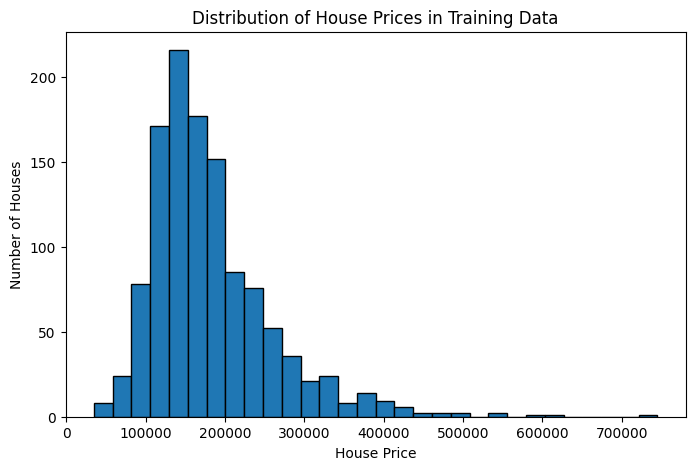

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(y_train, bins=30, edgecolor="black")

plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices in Training Data")

plt.show()